# Feature Analysis (Anchor-level) for Real Matching Pipeline

This notebook evaluates five matching features (DTW, OT, Area, Aspect Ratio, Centroid distance) under an anchor-level setting.

Workflow:
1. Load high-confidence pairings and per-slice cell data.
2. Train models with grouped cross-validation (GroupKFold by anchor).
3. Report anchor-level metrics (Recall@K and rank statistics).
4. Generate two figures:
   - **Single Feature Performance**: Recall@1 of each feature for RF vs LR (bar chart).
   - **RF vs LR Across Feature Counts**: Recall@1 and Mean Rank vs number of features (scatter + mean±std).

In [1]:
import re
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import matplotlib as mpl

from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GroupKFold
from sklearn.preprocessing import StandardScaler

from scipy import stats  # (not used in this script currently, but kept if you extend)

%matplotlib inline

# Plot styling 
plt.rcParams["font.family"] = "DejaVu Sans"
plt.rcParams["font.size"] = 7
plt.rcParams["axes.linewidth"] = 0.5
plt.rcParams["xtick.major.width"] = 0.5
plt.rcParams["ytick.major.width"] = 0.5
plt.rcParams["figure.dpi"] = 300
plt.rcParams["pdf.fonttype"] = 42
plt.rcParams["ps.fonttype"] = 42
plt.rcParams["text.usetex"] = False
plt.rcParams["mathtext.default"] = "regular"

In [2]:
from cell_matching_utils import (
    load_cells_from_csv_files,
    dtw_distance_gpu_single,
    get_cluster_cells,
    compute_ot_cost_matrix,
    solve_optimal_transport,
    DTW_NORM_DIVISOR,
    OT_NORM_DIVISOR,
    CENTROID_NORM_DIVISOR,
)

import cell_matching_utils as recon_module

def solve_ot_with_adaptive_reg(C, weights_a, weights_b):
    adaptive_reg = max(np.max(C) / 10.0, 50000.0)
    original_reg = recon_module.SINKHORN_REG
    recon_module.SINKHORN_REG = adaptive_reg
    ot_distance, T = recon_module.solve_optimal_transport(C, weights_a, weights_b, use_gpu=True)
    recon_module.SINKHORN_REG = original_reg
    return ot_distance, T

In [4]:
FEATURE_NAMES = ["dtw_loss", "ot_loss", "area_loss", "aspect_ratio_loss", "centroid_loss"]
FEATURE_DISPLAY_NAMES = ["DTW", "OT", "Area", "Aspect Ratio", "Centroid"]

WINDOW_SIZE = 200

In [5]:
def calculate_5_features(cell1, cell2, cells_by_slice, dtw_scale=None, ot_scale=None):
    if dtw_scale is None:
        dtw_scale = DTW_NORM_DIVISOR
    if ot_scale is None:
        ot_scale = OT_NORM_DIVISOR
    
    features = {}
    
    # DTW
    if hasattr(cell1, "contour_points_200") and hasattr(cell2, "contour_points_200"):
        dtw_raw = dtw_distance_gpu_single(cell1.contour_points_200, cell2.contour_points_200)
    else:
        dtw_raw = dtw_distance_gpu_single(cell1.contour_points, cell2.contour_points)
    features["dtw_loss"] = min(10.0, dtw_raw / dtw_scale * 10.0)
    
    # OT
    cluster1 = get_cluster_cells(cell1, cells_by_slice)
    cluster2 = get_cluster_cells(cell2, cells_by_slice)
    if len(cluster1) > 1 and len(cluster2) > 1:
        C = compute_ot_cost_matrix(cluster1, cluster2)
        areas1 = np.array([c.area for c in cluster1])
        areas2 = np.array([c.area for c in cluster2])
        weights1 = areas1 / areas1.sum()
        weights2 = areas2 / areas2.sum()
        ot_raw, _ = solve_ot_with_adaptive_reg(C, weights1, weights2)
        features["ot_loss"] = min(10.0, ot_raw / ot_scale * 10.0)
    else:
        features["ot_loss"] = 0.0
    
    # Area
    area_ratio = min(cell1.area, cell2.area) / max(cell1.area, cell2.area)
    features["area_loss"] = (1.0 - area_ratio) * 10.0
    
    # Aspect ratio
    aspect_diff = abs(cell1.aspect_ratio - cell2.aspect_ratio)
    features["aspect_ratio_loss"] = min(10.0, aspect_diff * 2.5)
    
    # Centroid
    cx1, cy1 = cell1.centroid
    cx2, cy2 = cell2.centroid
    centroid_dist = np.sqrt((cx2 - cx1)**2 + (cy2 - cy1)**2)
    features["centroid_loss"] = min(10.0, centroid_dist / CENTROID_NORM_DIVISOR * 10.0)
    
    return features

In [6]:
def construct_anchor_grouped_dataset(golden_df, cells_by_slice, window_size=100):
    samples = []
    window_half = window_size / 2.0
    
    for idx, row in golden_df.iterrows():
        start_layer = row["Start_layer"]
        end_layer = row["End_layer"]
        start_cell_id = row["Start_cell"]
        true_match_id = row["End_cell"]
        
        if end_layer - start_layer != 1:
            continue
        
        anchor = None
        for c in cells_by_slice.get(start_layer, []):
            if c.cell_id == start_cell_id:
                anchor = c
                break
        if anchor is None:
            continue
        
        anchor_id = f"L{start_layer}_{start_cell_id}"
        candidates = cells_by_slice.get(end_layer, [])
        cx, cy = anchor.centroid
        
        for candidate in candidates:
            cx2, cy2 = candidate.centroid
            if abs(cx2 - cx) <= window_half and abs(cy2 - cy) <= window_half:
                feats = calculate_5_features(anchor, candidate, cells_by_slice)
                feats["label"] = 1 if candidate.cell_id == true_match_id else 0
                feats["anchor_id"] = anchor_id
                feats["start_layer"] = start_layer
                feats["end_layer"] = end_layer
                feats["start_cell_id"] = start_cell_id
                feats["end_cell_id"] = candidate.cell_id
                samples.append(feats)
    
    df = pd.DataFrame(samples)
    print(f"Dataset: {df['anchor_id'].nunique()} anchors, "
          f"{(df['label']==1).sum()} positives, {(df['label']==0).sum()} negatives")
    return df

In [7]:
def evaluate_anchor_level_performance(y_true, y_pred_score, anchor_ids, k_values=(1, 3, 5)):
    results = {}
    unique_anchors = np.unique(anchor_ids)
    
    for k in k_values:
        correct = 0
        total = 0
        for aid in unique_anchors:
            mask = anchor_ids == aid
            labels = y_true[mask]
            scores = y_pred_score[mask]
            if labels.sum() == 0:
                continue
            top_k = np.argsort(scores)[-k:]
            if labels[top_k].sum() > 0:
                correct += 1
            total += 1
        results[f"Recall@{k}"] = correct / total
    
    ranks = []
    for aid in unique_anchors:
        mask = anchor_ids == aid
        labels = y_true[mask]
        scores = y_pred_score[mask]
        if labels.sum() == 0:
            continue
        sorted_idx = np.argsort(scores)[::-1]
        true_idx = np.where(labels == 1)[0][0]
        rank = np.where(sorted_idx == true_idx)[0][0] + 1
        ranks.append(rank)
    
    results["Mean_Rank"] = np.mean(ranks)
    results["Median_Rank"] = np.median(ranks)
    return results

In [8]:
def train_and_evaluate_anchor_level(df, model_type="rf"):
    drop_cols = ["label", "anchor_id", "start_layer", "end_layer", "start_cell_id", "end_cell_id"]
    feature_cols = [c for c in df.columns if c not in drop_cols]
    
    X = df[feature_cols].values
    y = df["label"].values
    anchor_ids = df["anchor_id"].values
    
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X)
    
    if model_type == "rf":
        model = RandomForestClassifier(n_estimators=100, max_depth=10, random_state=42,
                                      class_weight="balanced", n_jobs=-1)
    else:
        model = LogisticRegression(max_iter=1000, random_state=42, class_weight="balanced")
    
    gkf = GroupKFold(n_splits=5)
    y_pred_scores = np.zeros(len(y))
    
    for train_idx, val_idx in gkf.split(X_scaled, y, groups=anchor_ids):
        X_train, X_val = X_scaled[train_idx], X_scaled[val_idx]
        y_train = y[train_idx]
        model.fit(X_train, y_train)
        y_pred_scores[val_idx] = model.predict_proba(X_val)[:, 1]
    
    metrics = evaluate_anchor_level_performance(y, y_pred_scores, anchor_ids, k_values=(1, 3, 5))
    return metrics, y_pred_scores

In [9]:
from itertools import combinations

def analyze_single_and_combinations(df):
    results = []
    
    # Single features
    for i, disp_name in enumerate(FEATURE_DISPLAY_NAMES):
        feat_col = FEATURE_NAMES[i]
        for model_type, model_label in (("rf", "RF"), ("lr", "LR")):
            sub_df = df[[feat_col, "label", "anchor_id"]].copy()
            metrics, _ = train_and_evaluate_anchor_level(sub_df, model_type)
            results.append({"combination": disp_name, "num_features": 1, 
                          "model": model_label, **metrics})
    
    # Pairs
    for pair_idx in combinations(range(5), 2):
        pair_names = [FEATURE_DISPLAY_NAMES[i] for i in pair_idx]
        pair_cols = [FEATURE_NAMES[i] for i in pair_idx]
        combo_name = "+".join(pair_names)
        
        for model_type, model_label in (("rf", "RF"), ("lr", "LR")):
            sub_df = df[pair_cols + ["label", "anchor_id"]].copy()
            metrics, _ = train_and_evaluate_anchor_level(sub_df, model_type)
            results.append({"combination": combo_name, "num_features": 2,
                          "model": model_label, **metrics})
    
    # Triples
    for triple_idx in combinations(range(5), 3):
        triple_names = [FEATURE_DISPLAY_NAMES[i] for i in triple_idx]
        triple_cols = [FEATURE_NAMES[i] for i in triple_idx]
        combo_name = "+".join(triple_names)
        
        for model_type, model_label in (("rf", "RF"), ("lr", "LR")):
            sub_df = df[triple_cols + ["label", "anchor_id"]].copy()
            metrics, _ = train_and_evaluate_anchor_level(sub_df, model_type)
            results.append({"combination": combo_name, "num_features": 3,
                          "model": model_label, **metrics})
    
    # 4-feature combinations
    for quad_idx in combinations(range(5), 4):
        quad_names = [FEATURE_DISPLAY_NAMES[i] for i in quad_idx]
        quad_cols = [FEATURE_NAMES[i] for i in quad_idx]
        combo_name = "+".join(quad_names)
        
        for model_type, model_label in (("rf", "RF"), ("lr", "LR")):
            sub_df = df[quad_cols + ["label", "anchor_id"]].copy()
            metrics, _ = train_and_evaluate_anchor_level(sub_df, model_type)
            results.append({"combination": combo_name, "num_features": 4,
                          "model": model_label, **metrics})
    
    # All 5 features
    for model_type, model_label in (("rf", "RF"), ("lr", "LR")):
        metrics, _ = train_and_evaluate_anchor_level(df, model_type)
        results.append({"combination": "All 5", "num_features": 5,
                      "model": model_label, **metrics})
    
    return pd.DataFrame(results)

In [10]:
def plot_single_feature_performance(results_df, out_pdf="figure2_single_feature_performance.pdf"):
    fig, ax = plt.subplots(1, 1, figsize=(5, 3.5))
    
    single_rf = results_df[(results_df["num_features"] == 1) & (results_df["model"] == "RF")]
    single_lr = results_df[(results_df["num_features"] == 1) & (results_df["model"] == "LR")]
    
    x = np.arange(5)
    width = 0.35
    
    ax.bar(x - width/2, single_rf["Recall@1"].values, width, label="Random Forest",
           color="#D62246", edgecolor="black", linewidth=0.5, alpha=0.8)
    ax.bar(x + width/2, single_lr["Recall@1"].values, width, label="Logistic Regression",
           color="#06A77D", edgecolor="black", linewidth=0.5, alpha=0.8)
    
    ax.set_xticks(x)
    ax.set_xticklabels(FEATURE_DISPLAY_NAMES, fontsize=7, rotation=15, ha="right")
    ax.set_ylabel("Recall@1", fontsize=8)
    ax.set_title("Single Feature Performance", fontsize=9, fontweight="bold")
    ax.legend(fontsize=7, loc="upper left")
    ax.grid(True, alpha=0.3, linewidth=0.5, axis="y")
    ax.set_ylim([0, 1.0])
    
    plt.tight_layout()
    fig.savefig(out_pdf, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close()

In [11]:
def plot_rf_lr_combinations(results_df, out_pdf="rf_lr_combinations.pdf"):
    fig, axes = plt.subplots(1, 2, figsize=(7, 3.2))
    
    color_rf = "#E63946"
    color_lr = "#457B9D"
    
    # Recall@1
    ax = axes[0]
    for model_name, color, marker in (("RF", color_rf, "o"), ("LR", color_lr, "s")):
        num_features_list, recall_means, recall_stds = [], [], []
        
        for num_feat in (1, 2, 3, 4, 5):
            subset = results_df[(results_df["num_features"] == num_feat) & 
                              (results_df["model"] == model_name)]
            if len(subset) == 0:
                continue
            
            recalls = subset["Recall@1"].values
            num_features_list.append(num_feat)
            recall_means.append(recalls.mean())
            recall_stds.append(recalls.std())
            
            x_jitter = np.random.normal(0, 0.05, len(recalls))
            ax.scatter(num_feat + x_jitter, recalls, s=20, alpha=0.3, 
                      color=color, edgecolor="none")
        
        ax.errorbar(num_features_list, recall_means, yerr=recall_stds,
                   fmt=marker + "-", color=color, linewidth=2, markersize=8,
                   capsize=4, label=model_name, zorder=10)
    
    ax.set_xlabel("Number of Features", fontsize=9, fontweight="bold")
    ax.set_ylabel("Recall@1", fontsize=9, fontweight="bold")
    ax.set_xticks([1, 2, 3, 4, 5])
    ax.legend(fontsize=8, loc="lower right")
    ax.grid(True, alpha=0.25, linewidth=0.5, linestyle="--")
    ax.set_ylim([0, 1.05])
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    
    # Mean Rank
    ax = axes[1]
    for model_name, color, marker in (("RF", color_rf, "o"), ("LR", color_lr, "s")):
        num_features_list, rank_means, rank_stds = [], [], []
        
        for num_feat in (1, 2, 3, 4, 5):
            subset = results_df[(results_df["num_features"] == num_feat) & 
                              (results_df["model"] == model_name)]
            if len(subset) == 0:
                continue
            
            ranks = subset["Mean_Rank"].values
            num_features_list.append(num_feat)
            rank_means.append(ranks.mean())
            rank_stds.append(ranks.std())
            
            x_jitter = np.random.normal(0, 0.05, len(ranks))
            ax.scatter(num_feat + x_jitter, ranks, s=20, alpha=0.3,
                      color=color, edgecolor="none")
        
        ax.errorbar(num_features_list, rank_means, yerr=rank_stds,
                   fmt=marker + "-", color=color, linewidth=2, markersize=8,
                   capsize=4, label=model_name, zorder=10)
    
    ax.set_xlabel("Number of Features", fontsize=9, fontweight="bold")
    ax.set_ylabel("Mean Rank", fontsize=9, fontweight="bold")
    ax.set_xticks([1, 2, 3, 4, 5])
    ax.legend(fontsize=8, loc="upper right")
    ax.grid(True, alpha=0.25, linewidth=0.5, linestyle="--")
    ax.invert_yaxis()
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    
    plt.tight_layout()
    fig.savefig(out_pdf, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close()

In [12]:
GOLDEN_CSV = "High_confidence_pairing_4nums_fullnames.csv"
CELLS_DIR = "cell-002_processed"
OUT_DATASET_CSV = "anchor_grouped_dataset.csv"
OUT_RESULTS_CSV = "feature_combinations_results.csv"

In [13]:
golden_df = pd.read_csv(GOLDEN_CSV)
cells_by_slice = load_cells_from_csv_files(CELLS_DIR)

Loading from cell-002_processed: found 15 CSV files


Loading CSV files: 100%|██████████| 15/15 [01:16<00:00,  5.10s/it]


Total cells loaded: 12009


In [14]:
df = construct_anchor_grouped_dataset(golden_df, cells_by_slice, window_size=WINDOW_SIZE)
df.to_csv(OUT_DATASET_CSV, index=False)
df.head()

Dataset: 338 anchors, 331 positives, 6484 negatives


,dtw_loss,ot_loss,area_loss,aspect_ratio_loss,centroid_loss,label,anchor_id,start_layer,end_layer,start_cell_id,end_cell_id
0,6.999436,10.000000,0.199018,0.937143,8.568426,0,L14_lighter_14-cell-002-roi5443,14,15,lighter_14-cell-002-roi5443,lighter_15-cell-002-roi5338
1,10.000000,10.000000,0.908323,4.604772,10.000000,0,L14_lighter_14-cell-002-roi5443,14,15,lighter_14-cell-002-roi5443,lighter_15-cell-002-roi5356
2,8.581730,9.871528,5.552607,1.256709,10.000000,0,L14_lighter_14-cell-002-roi5443,14,15,lighter_14-cell-002-roi5443,lighter_15-cell-002-roi5428
3,1.343388,7.108326,2.344434,0.490318,0.684350,1,L14_lighter_14-cell-002-roi5443,14,15,lighter_14-cell-002-roi5443,lighter_15-cell-002-roi5479
4,3.813503,6.642391,2.102959,1.582930,9.565088,0,L14_lighter_14-cell-002-roi5443,14,15,lighter_14-cell-002-roi5443,lighter_15-cell-002-roi5484


In [15]:
results_df = analyze_single_and_combinations(df)
results_df.to_csv(OUT_RESULTS_CSV, index=False)
results_df.head()

,combination,num_features,model,Recall@1,Recall@3,Recall@5,Mean_Rank,Median_Rank
0,DTW,1,RF,0.413897,0.655589,0.773414,4.012085,2.0
1,DTW,1,LR,0.516616,0.752266,0.867069,2.906344,1.0
2,OT,1,RF,0.111782,0.232628,0.350453,9.196375,8.0
3,OT,1,LR,0.163142,0.371601,0.537764,6.380665,5.0
4,Area,1,RF,0.151057,0.404834,0.570997,5.888218,5.0


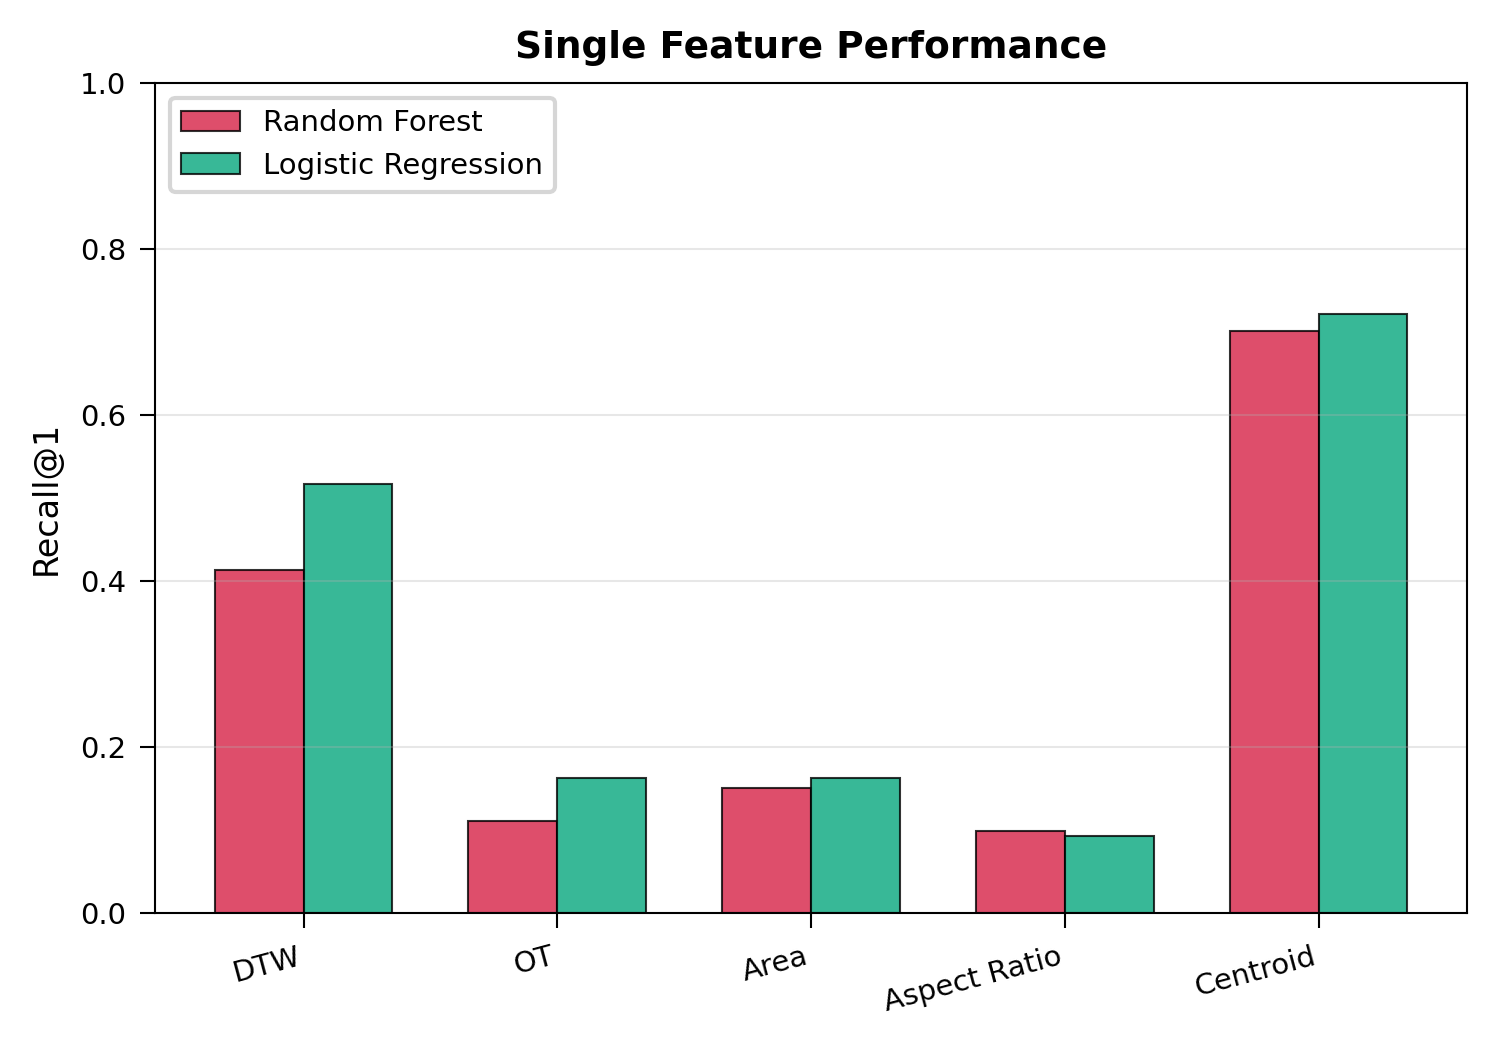

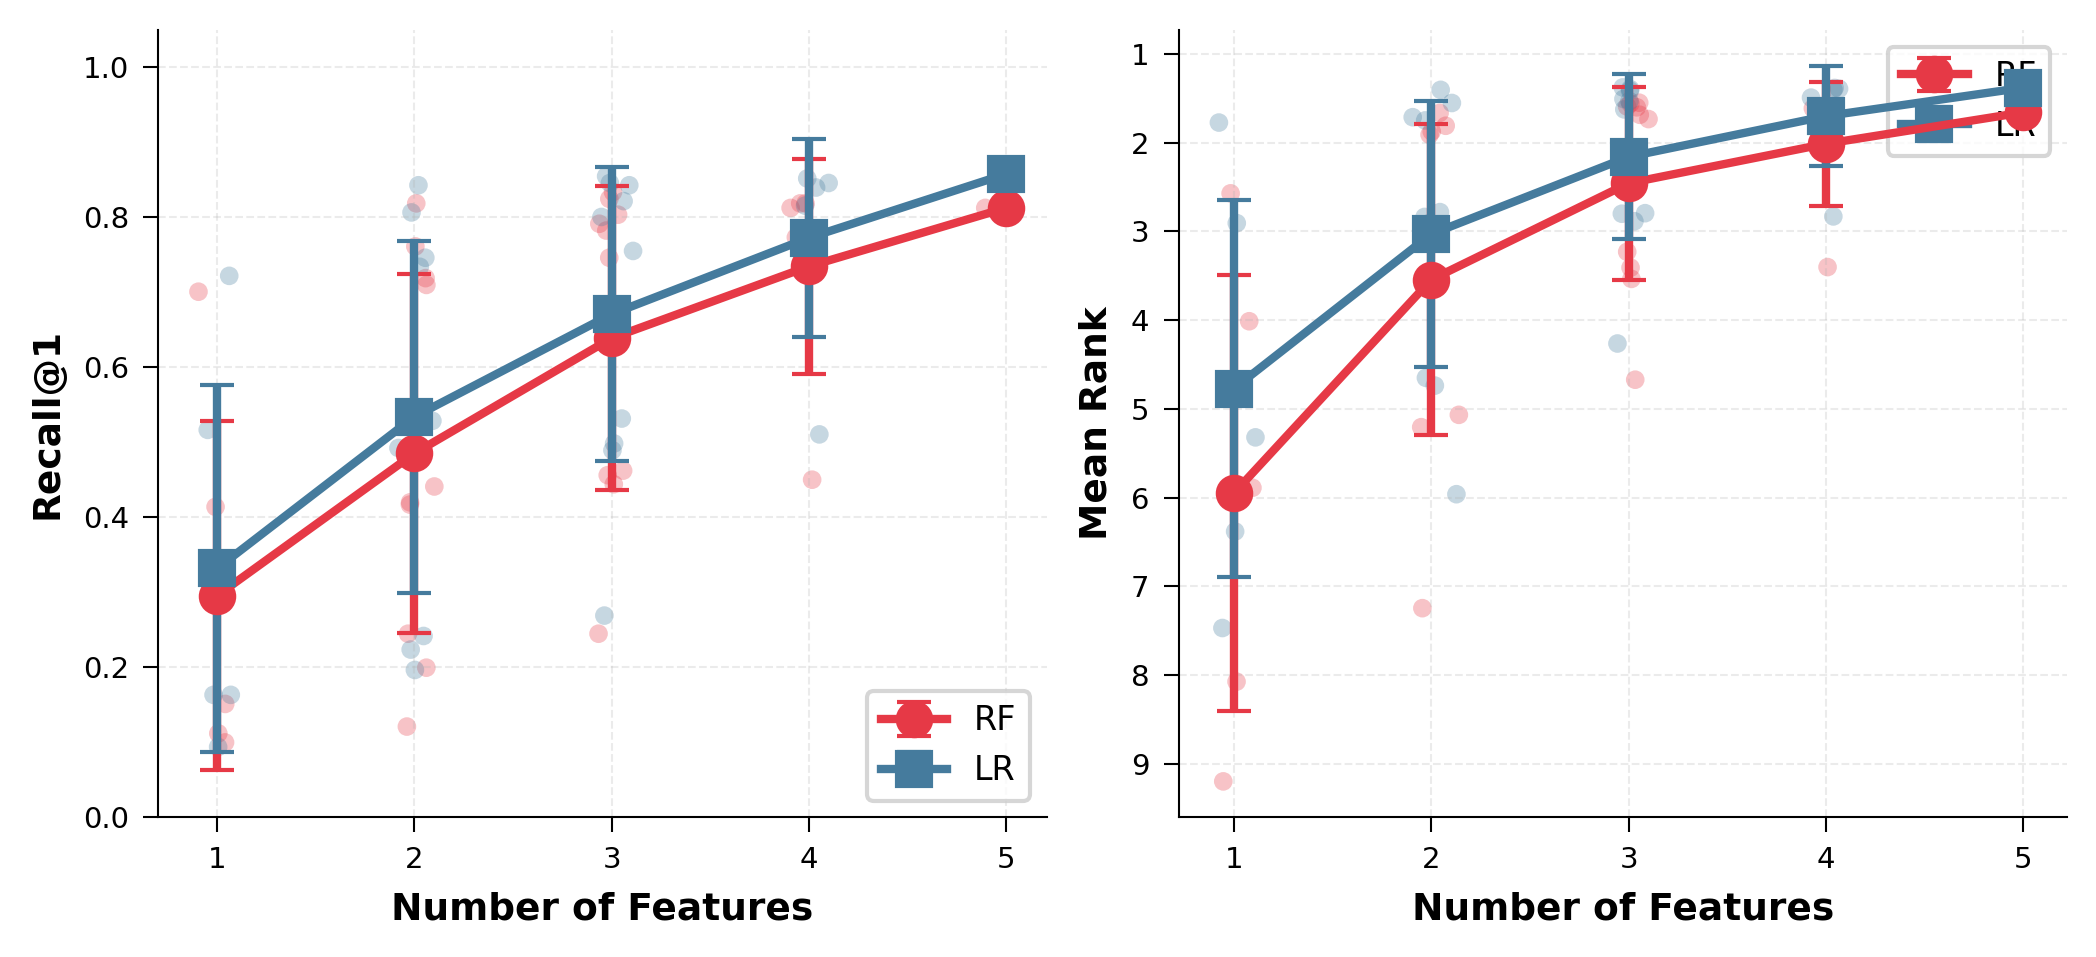

In [16]:
plot_single_feature_performance(results_df, out_pdf="single_feature_performance.pdf")
plot_rf_lr_combinations(results_df, out_pdf="rf_lr_combinations.pdf")